In [1]:
from typing import Literal

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import seaborn as sns
from dtaianomaly.utils import get_dimension

from hydraad import TSBADLoader

In [2]:
sns.set_theme()

In [3]:
def load_results(mode: Literal["M", "U"]) -> pd.DataFrame:
    results = pd.read_csv(f"../results/scalability/TSB-AD-{mode}.csv", index_col="file")

    results["Length"] = pd.NA
    results["Dimension"] = pd.NA
    for file in results.index:
        dataset = TSBADLoader(f"../data/TSB-AD-{mode}/{file}").load()
        results.loc[file, "Length"] = dataset.X_test.shape[0]
        results.loc[file, "Dimension"] = get_dimension(dataset.X_test)

    return results

In [4]:
df_uni = load_results("U")
df_multi = load_results("M")

In [5]:
print(
    f"Total time on TSB-AD-U with CPU: {df_uni[df_uni['Device'] == 'CPU']['Run time [s]'].sum():.4f} seconds"
)
print(
    f"Total time on TSB-AD-U with GPU: {df_uni[df_uni['Device'] == 'GPU']['Run time [s]'].sum():.4f} seconds"
)
print(
    f"Total time on TSB-AD-M with CPU: {df_multi[df_multi['Device'] == 'CPU']['Run time [s]'].sum():.4f} seconds"
)
print(
    f"Total time on TSB-AD-M with GPU: {df_multi[df_multi['Device'] == 'GPU']['Run time [s]'].sum():.4f} seconds"
)

Total time on TSB-AD-U with CPU: 124.8157 seconds
Total time on TSB-AD-U with GPU: 7.4587 seconds
Total time on TSB-AD-M with CPU: 2505.2026 seconds
Total time on TSB-AD-M with GPU: 32.0537 seconds


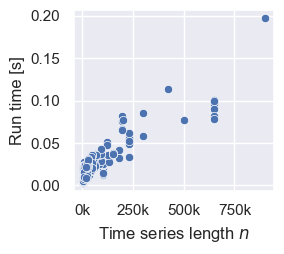

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(3, 2.7))
sns.scatterplot(
    data=df_uni[df_uni["Device"] == "GPU"], x="Length", y="Run time [s]", ax=ax
)
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f"{x / 1000:.0f}k"))
ax.set_xlabel("Time series length $n$")

fig.tight_layout()
fig.savefig("figures/fig-scalability-tsb-ad-u.png", bbox_inches="tight")

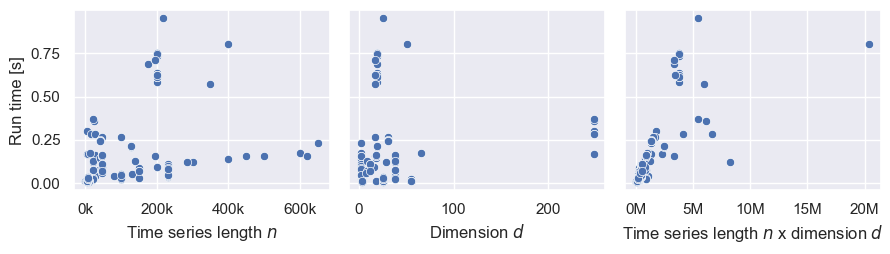

In [7]:
fig, axs = plt.subplots(1, 3, figsize=(9, 2.7), sharey="all")

sns.scatterplot(
    data=df_multi[df_multi["Device"] == "GPU"], x="Length", y="Run time [s]", ax=axs[0]
)
axs[0].set_xlabel("Time series length $n$")

sns.scatterplot(
    data=df_multi[df_multi["Device"] == "GPU"],
    x="Dimension",
    y="Run time [s]",
    ax=axs[1],
)
axs[1].set_xlabel("Dimension $d$")

df_multi["Length x Dimension"] = df_multi["Length"] * df_multi["Dimension"]
sns.scatterplot(
    data=df_multi[df_multi["Device"] == "GPU"],
    x="Length x Dimension",
    y="Run time [s]",
    ax=axs[2],
)
axs[2].set_xlabel("Time series length $n$ x dimension $d$")

axs[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x / 1000:.0f}k")
)
axs[2].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x / 1_000_000:.0f}M")
)

fig.tight_layout()
fig.savefig("figures/fig-scalability-tsb-ad-m.png", bbox_inches="tight")

LENGTH
Max run time for CPU: 20.84 seconds
Max run time for GPU: 0.85 seconds

DIMENSION
Max run time for CPU: 12.40 seconds
Max run time for GPU: 0.77 seconds


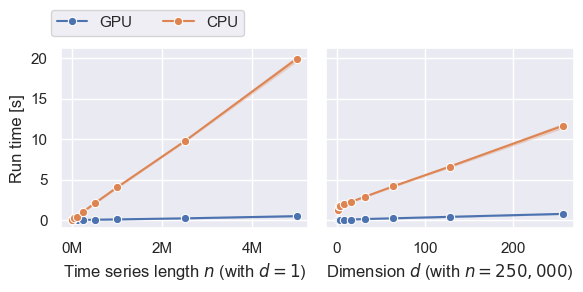

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(6, 2.7), sharey="all")

df = pd.read_csv("../results/scalability/length-time.csv")
df["Run time [s]"] = df["Run time [ms]"] / 1000
print("LENGTH")
print(
    f"Max run time for CPU: {df[df['Device'] == 'CPU']['Run time [s]'].max():.2f} seconds"
)
print(
    f"Max run time for GPU: {df[df['Device'] == 'GPU']['Run time [s]'].max():.2f} seconds"
)
sns.lineplot(
    data=df,
    x="Length",
    y="Run time [s]",
    hue="Device",
    hue_order=["GPU", "CPU"],
    marker="o",
    ax=axs[0],
)
axs[0].set_xlabel("Time series length $n$ (with $d=1$)")
axs[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x / 1_000_000:.0f}M")
)

df = pd.read_csv("../results/scalability/dimension-time.csv")
df["Run time [s]"] = df["Run time [ms]"] / 1000
print("\nDIMENSION")
print(
    f"Max run time for CPU: {df[df['Device'] == 'CPU']['Run time [s]'].max():.2f} seconds"
)
print(
    f"Max run time for GPU: {df[df['Device'] == 'GPU']['Run time [s]'].max():.2f} seconds"
)
sns.lineplot(
    data=df,
    x="Dimension",
    y="Run time [s]",
    hue="Device",
    hue_order=["GPU", "CPU"],
    marker="o",
    ax=axs[1],
)
axs[1].set_xlabel("Dimension $d$ (with $n=250,000$)")

# axs[0].set_yscale("log")
# axs[0].set_ylabel("Run time [s] (log scale)")

handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower left", bbox_to_anchor=(0.085, 0.95), ncol=2)
axs[0].get_legend().remove()
axs[1].get_legend().remove()

fig.tight_layout()
fig.savefig("figures/fig-scalability-time.png", bbox_inches="tight")

LENGTH
Peak memory: 17.09 GB
DIMENSION
Peak memory: 6.91 GB


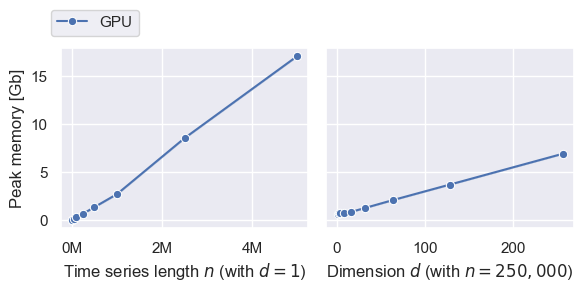

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(6, 2.7), sharey="all")

df = pd.read_csv("../results/scalability/length-memory.csv")
df["Device"] = "GPU"
df["Peak memory [Gb]"] = df["Peak memory [Mb]"] / 1024
sns.lineplot(
    data=df, x="Length", y="Peak memory [Gb]", marker="o", ax=axs[0], hue="Device"
)
axs[0].set_xlabel("Time series length $n$ (with $d=1$)")
print("LENGTH")
print(f"Peak memory: {df['Peak memory [Gb]'].max():.2f} GB")


df = pd.read_csv("../results/scalability/dimension-memory.csv")
df["Peak memory [Gb]"] = df["Peak memory [Mb]"] / 1024
sns.lineplot(data=df, x="Dimension", y="Peak memory [Gb]", marker="o", ax=axs[1])
axs[1].set_xlabel("Dimension $d$ (with $n=250,000$)")
print("DIMENSION")
print(f"Peak memory: {df['Peak memory [Gb]'].max():.2f} GB")

# Add a legend with label "GPU"
handles, labels = axs[0].get_legend_handles_labels()
fig.legend(handles, ["GPU"], loc="lower left", bbox_to_anchor=(0.085, 0.95))
axs[0].get_legend().remove()

axs[0].xaxis.set_major_formatter(
    ticker.FuncFormatter(lambda x, pos: f"{x / 1_000_000:.0f}M")
)

fig.tight_layout()
fig.savefig("figures/fig-scalability-memory.png", bbox_inches="tight")

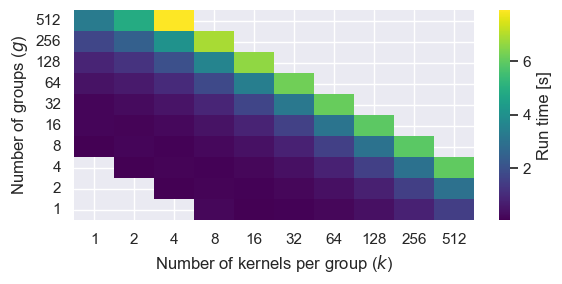

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

df = pd.read_csv("../results/scalability/number_kernels-time.csv")
df["Run time [s]"] = df["Run time [ms]"] / 1000

pivot_table = df.pivot_table(
    values="Run time [s]", index="n_groups", columns="n_kernels"
)
sns.heatmap(pivot_table, annot=False, fmt=".2f", ax=ax, cmap="viridis")
ax.invert_yaxis()
ax.collections[0].colorbar.set_label("Run time [s]")

ax.set_xlabel("Number of kernels per group ($k$)")
ax.set_ylabel("Number of groups ($g$)")

fig.tight_layout()
fig.savefig("figures/fig-scalability-number-kernels-heatmap.png", bbox_inches="tight")

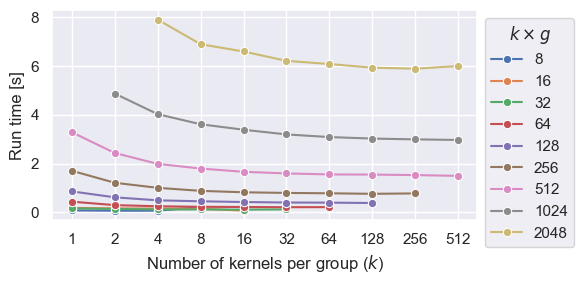

In [11]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

df = pd.read_csv("../results/scalability/number_kernels-time.csv")
df["Run time [s]"] = df["Run time [ms]"] / 1000

df["n_groups x n_kernels"] = (df["n_groups"] * df["n_kernels"]).astype(str)
df["n_kernels"] = df["n_kernels"].astype(str)
df["n_kernels"] = pd.Categorical(
    df["n_kernels"],
    categories=sorted(df["n_kernels"].unique(), key=lambda x: int(x)),
    ordered=True,
)
sns.lineplot(
    data=df,
    x="n_kernels",
    hue="n_groups x n_kernels",
    y="Run time [s]",
    marker="o",
    ax=ax,
    errorbar=None,
)
ax.legend(title=r"$k \times g$", loc="upper left", bbox_to_anchor=(1, 1))

ax.set_xlabel("Number of kernels per group ($k$)")

fig.tight_layout()
fig.savefig("figures/fig-scalability-number-kernels-lineplot.png", bbox_inches="tight")

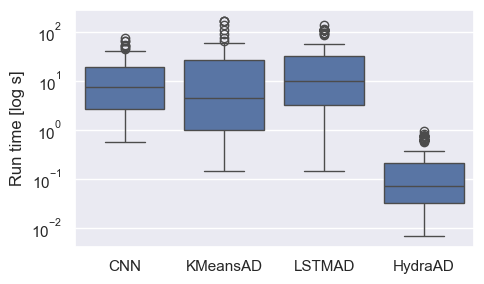

In [12]:
df_m_cnn = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/CNN.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_m_kmeans_ad = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/KMeansAD.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_m_lstmad = pd.read_csv("../results/TSB-AD/reproduced/run_time_M/LSTMAD.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_multi_ = df_multi[df_multi["Device"] == "GPU"].copy()

# PLot the runtimes of all methods in a boxxplot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
df_m_cnn["Method"] = "CNN"
df_m_kmeans_ad["Method"] = "KMeansAD"
df_m_lstmad["Method"] = "LSTMAD"
df_multi_["Method"] = "HydraAD"
df_all = pd.concat([df_m_cnn, df_m_kmeans_ad, df_m_lstmad, df_multi_[["Run time [s]", "Method"]]], ignore_index=True)
sns.boxplot(data=df_all, x="Method", y="Run time [s]", ax=ax)
ax.set_yscale("log")
ax.set_ylabel("Run time [log s]")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig("figures/fig-scalability-tsb-ad-m-boxplot.png", bbox_inches="tight")

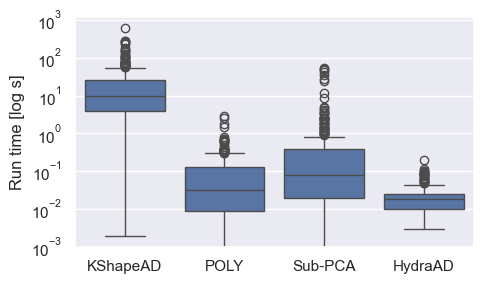

In [13]:
# Load the reproduced results for TSB-AD-U and TSB-AD-M
df_u_kshapead = pd.read_csv("../results/TSB-AD/reproduced/run_time_U/KShapeAD.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_u_poly = pd.read_csv("../results/TSB-AD/reproduced/run_time_U/POLY.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_u_pca = pd.read_csv("../results/TSB-AD/reproduced/run_time_U/Sub-PCA.csv")[["Runtime [s]"]].rename(columns={"Runtime [s]": "Run time [s]"})
df_uni_ = df_uni[df_uni["Device"] == "GPU"].copy()

# PLot the runtimes of all methods in a boxxplot
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
df_u_kshapead["Method"] = "KShapeAD"
df_u_poly["Method"] = "POLY"
df_u_pca["Method"] = "Sub-PCA"
df_uni_["Method"] = "HydraAD"
df_all = pd.concat([df_u_kshapead, df_u_poly, df_u_pca, df_uni_[["Run time [s]", "Method"]]], ignore_index=True)
sns.boxplot(data=df_all, x="Method", y="Run time [s]", ax=ax)
ax.set_yscale("log")
ax.set_ylabel("Run time [log s]")
ax.set_xlabel("")
fig.tight_layout()
fig.savefig("figures/fig-scalability-tsb-ad-u-boxplot.png", bbox_inches="tight")